# Internal Replication and Random-Effects Pooling — One Expansion State at a Time

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 1-year detail table B27010, 2010–2019 (each year pinned)

This notebook uses **real data only**. There is no synthetic generator and no fallback. If a retrieval fails, a key is
absent or a value leaves its stated range, the notebook stops.

The analysis was fixed in a **pre-analysis plan** (`pap/M01_pap.md`) committed before any table below was retrieved. The notebook
is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Re-estimate** one design in each jurisdiction separately and treat the results as studies, with an estimate and a standard error each.
2. **Pool** them under fixed and random effects, and say what each pooled number is the mean *of*.
3. **Read** heterogeneity as a finding: Cochran's Q, τ², I², and the prediction interval for the effect in a state not yet seen.
4. **Use** a funnel plot, Egger's test and leave-one-out pooling, and say what each can and cannot show with this many estimates.
5. **Say** why the pooled interval here is too narrow: the state estimates share one control group, so they are not independent.

## Prerequisites

**Knowledge.** The C01 design (a difference-in-differences against the never-expanded states). What a standard error and a margin of error are.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the environment variable
`CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`. The key is read at runtime
and is never printed or written into this notebook's output.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package (its `methods.meta`
module holds the pooling, and its `uncertainty` module the margin-of-error arithmetic).

**Prior notebooks.** C01, whose stored output is read below, not re-run.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `B27010_034E`, `B27010_050E` and their margins of error | ACS 1-year detail table B27010, state × year | uninsured rate, ages 35–64 (outcome) |
| `B27010_051E`, `B27010_066E` and their margins of error | the same table | uninsured rate, ages 65 and over (placebo outcome) |
| `data/policy/medicaid/expansion_dates.csv` | KFF, *Status of State Action on the Medicaid Expansion Decision* | treatment timing, C01's assignment |
| C01's stored output | `projects/09-causal-identification/C01_medicaid_expansion_did/` | the reference estimate, read from the file |

The table, variables and age band are C01's. What is new is the published **margin of error** of each count, which sets each state estimate's standard error.
The Census Bureau publishes no standard 2020 ACS 1-year release, so 2020 is absent. Every variable's published label for each year is retrieved and
recorded in that year's provenance file, together with the SHA-256 of the pre-analysis plan.

## Design and identification

**Estimand.** For each of the states that expanded on 1 January 2014: the change in its uninsured rate (adults 35–64, mean of 2014–2019 minus mean of 2010–2013) minus the mean change in
the never-expanded states, in percentage points. The pooled estimand is the **mean of the distribution of state effects**; the fixed-effect version is the one common effect, which the data may not support.

**Assumption.** Parallel trends between each expansion state and the never-expanded states, with the same control pool for every state. It is tested only through two placebos.

**Standard errors.** Each state estimate's standard error is a *sampling* error, built from the published margins of error, with the years treated as independent samples. The control group's sampling error
is the same in every state's estimate, so the 25 estimates are correlated. Differences between states that sampling error does not explain are the between-state variance, τ², which is the finding of interest.

**Decision rules, fixed in the plan.** The pooled effect is *not distinguishable from zero* if its 95% random-effects interval contains zero. Heterogeneity counts as a finding if Cochran's Q rejects at the 10% level. The pooled
effect is read as identified only if both placebo intervals contain zero.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data import uncertainty
from krl_tutorials_data.methods import meta
from krl_tutorials_data.sources import DataAccessError, fetch_acs

NB_DIR = REPO_ROOT / "projects" / "13-evidence-synthesis" / "M01_state_replication_pooling"
PAP = NB_DIR / "pap" / "M01_pap.md"
PAP_SHA256 = hashlib.sha256(PAP.read_bytes()).hexdigest()
C01_NB = REPO_ROOT / "projects" / "09-causal-identification" / "C01_medicaid_expansion_did" / "C01_medicaid_expansion_did.ipynb"

YEARS = list(range(2010, 2020))                       # no standard 2020 ACS 1-year; the plan uses 2010-2019 only
PRE, POST = [y for y in YEARS if y <= 2013], [y for y in YEARS if y >= 2014]
PLACEBO_PRE, PLACEBO_POST = [2010, 2011], [2012, 2013]
Q_LEVEL = 0.10                                       # heterogeneity threshold fixed in the plan


def pf(p: float) -> str:
    """A p-value for printing: very small values are not shown as zero."""
    return "p < 0.0001" if p < 1e-4 else f"p = {p:.4f}"


print(f"pre-analysis plan : {PAP.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PAP_SHA256}")
print(f"years retrieved   : {YEARS[0]}-{YEARS[-1]} ({len(YEARS)} vintages); main contrast {PRE[0]}-{PRE[-1]} to {POST[0]}-{POST[-1]}")

pre-analysis plan : projects/13-evidence-synthesis/M01_state_replication_pooling/pap/M01_pap.md
plan SHA-256      : c16fbbfe49a98d4f7bd5a4cde6da41c432a3d73e15a85d295b4d8722fb450b20
years retrieved   : 2010-2019 (10 vintages); main contrast 2010-2013 to 2014-2019


### The reference estimate, read from C01's stored output

C01 is not re-run. Its stored output is read from the file and its numbers are printed. The reference is **borderline**: the interval's upper end
is within a hair of zero, and the bootstrap verdict moves with the number of draws.

In [2]:
"""Read C01's stored estimate and its seed sensitivity from its notebook file."""
c01_cells = json.loads(C01_NB.read_text())["cells"]
c01_text = "\n".join(
    "".join(o.get("text", [])) for c in c01_cells if c["cell_type"] == "code" for o in c.get("outputs", [])
)
m_att = re.search(r"ATT \(TWFE\)\s*:\s*([+-]\d+\.\d+) pp", c01_text)
m_boot = re.search(r"wild-bootstrap p\s*:\s*(\d\.\d+)\s+95% CI \[([+-]\d+\.\d+), ([+-]\d+\.\d+)\]", c01_text)
m_seed = re.search(
    r"range of the bootstrap p across seeds at 99,999 draws: (\d\.\d+) to (\d\.\d+); upper interval end ([+-]\d\.\d+) to ([+-]\d\.\d+)",
    c01_text,
)
if not (m_att and m_boot and m_seed):
    raise SystemExit("C01's stored output does not hold the lines this notebook reads; stop and explain why.")
C01 = {
    "att": float(m_att.group(1)), "p": float(m_boot.group(1)),
    "lo": float(m_boot.group(2)), "hi": float(m_boot.group(3)),
    "p_seed_lo": float(m_seed.group(1)), "p_seed_hi": float(m_seed.group(2)),
    "hi_seed_lo": float(m_seed.group(3)), "hi_seed_hi": float(m_seed.group(4)),
}


def c01_banner() -> None:
    """Print C01's full interval and its borderline, seed-sensitive status."""
    print(f"C01 (read from its stored output, not re-run): ATT {C01['att']:+.3f} pp, wild-bootstrap 95% interval "
          f"[{C01['lo']:+.3f}, {C01['hi']:+.3f}], p = {C01['p']:.3f}.")
    print(f"  Borderline and seed-sensitive: the 9,999-draw interval contains zero (upper end {C01['hi']:+.3f}), while at 99,999 draws "
          f"p runs {C01['p_seed_lo']:.4f} to {C01['p_seed_hi']:.4f} and the upper end {C01['hi_seed_lo']:+.3f} to {C01['hi_seed_hi']:+.3f} across three seeds.")


c01_banner()

C01 (read from its stored output, not re-run): ATT -1.453 pp, wild-bootstrap 95% interval [-2.912, +0.006], p = 0.051.
  Borderline and seed-sensitive: the 9,999-draw interval contains zero (upper end +0.006), while at 99,999 draws p runs 0.0474 to 0.0482 and the upper end -0.020 to -0.013 across three seeds.


### Retrieving the data

One request per year to the ACS 1-year endpoint for that year, for the four counts and the margin of error published with each. For every year the notebook checks the published
label of each variable and stops if a label changes. Values outside a stated plausible range stop the notebook rather than flow into an estimate. Puerto Rico is returned by the API
and dropped later: the policy table covers the 50 states and the District of Columbia.

In [3]:
CODES = {
    "B27010_034E": "ages 35-64, total",
    "B27010_034M": "ages 35-64, total, margin of error",
    "B27010_050E": "ages 35-64, no health insurance coverage",
    "B27010_050M": "ages 35-64, no health insurance coverage, margin of error",
    "B27010_051E": "ages 65 and over, total",
    "B27010_051M": "ages 65 and over, total, margin of error",
    "B27010_066E": "ages 65 and over, no health insurance coverage",
    "B27010_066M": "ages 65 and over, no health insurance coverage, margin of error",
}
PLAUSIBLE = {
    "B27010_034E": (100_000, 20_000_000), "B27010_050E": (1_000, 5_000_000),
    "B27010_051E": (30_000, 10_000_000), "B27010_066E": (0, 500_000),   # near zero by design: Medicare covers almost everyone 65+
    "B27010_034M": (0, 5_000_000), "B27010_050M": (0, 2_000_000),
    "B27010_051M": (0, 3_000_000), "B27010_066M": (0, 500_000),
}


def published_labels(year: int) -> dict[str, str]:
    """The label the Census Bureau publishes for each variable in this vintage."""
    url = f"https://api.census.gov/data/{year}/acs/acs1/groups/B27010.json"   # the group listing carries the margin-of-error variables
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    variables = response.json()["variables"]
    return {code: variables[code]["label"] for code in CODES}


frames, records, label_by_year = [], {}, {}
try:
    for year in YEARS:
        labels = published_labels(year)
        label_by_year[year] = {c: l.replace(":", "").replace("Estimate!!", "").replace("Margin of Error!!", "") for c, l in labels.items()}
        frame, prov = fetch_acs(year=year, variables=labels, dataset="acs/acs1", geography="state:*", plausible=PLAUSIBLE)
        frame["year"] = year
        frames.append(frame)
        records[year] = prov.with_pap(PAP)
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

changed = [c for c in CODES if len({label_by_year[y][c] for y in YEARS}) > 1]
if changed:
    raise SystemExit(f"The published label of {changed} changes between years; stop and explain why.")

raw = pd.concat(frames, ignore_index=True)
out_dir = NB_DIR / "provenance"
for year, record in records.items():
    record.write(out_dir / f"m01_acs1_b27010_{year}.json")

print(f"variable codes    : {len(CODES)}; every published label is identical across the {len(YEARS)} vintages")
print(f"rows retrieved    : {len(raw):,} ({raw['year'].nunique()} years x {raw['NAME'].nunique()} geographies)")
print(f"records written   : {len(records)}, each bound to the plan digest {PAP_SHA256[:12]}...")
rec = records[2014]
print(f"2014 record       : endpoint {rec.endpoint}; {rec.row_count} rows; content SHA-256 {rec.content_sha256[:16]}...; plan SHA-256 {rec.pap_sha256[:16]}...")

variable codes    : 8; every published label is identical across the 10 vintages
rows retrieved    : 520 (10 years x 52 geographies)
records written   : 10, each bound to the plan digest c16fbbfe49a9...
2014 record       : endpoint https://api.census.gov/data/2014/acs/acs1; 52 rows; content SHA-256 c530cb6be525c4ba...; plan SHA-256 c16fbbfe49a98d4f...


### Treatment and sample

C01's assignment of states is applied unchanged.

In [4]:
"""C01's sample rule."""
policy = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")


def assign_group(row: pd.Series) -> str:
    if row["expansion_effective"] == "2014-01-01":
        return "treated"
    if row["status"] == "Not Adopted":
        return "control"
    if str(row["expansion_effective"]).startswith("2014"):
        return "excluded: partial first year"
    return "excluded: later adopter"


policy["group"] = policy.apply(assign_group, axis=1)
counts = policy["group"].value_counts()
EXPECTED = {"treated": 25, "control": 10, "excluded: partial first year": 2, "excluded: later adopter": 14}
if {k: int(counts.get(k, 0)) for k in EXPECTED} != EXPECTED:
    raise SystemExit("The sample does not match the pre-analysis plan; stop and explain why.")
print(f"Sample matches C01's: {EXPECTED['treated']} treated, {EXPECTED['control']} control, "
      f"{EXPECTED['excluded: partial first year'] + EXPECTED['excluded: later adopter']} excluded.")

panel = raw.rename(columns={"state": "fips"}).merge(policy[["state", "group"]], left_on="NAME", right_on="state", how="inner")
panel = panel[panel["group"].isin(["treated", "control"])].copy()
TREATED = sorted(panel.loc[panel["group"] == "treated", "state"].unique())
CONTROL = sorted(panel.loc[panel["group"] == "control", "state"].unique())
print(f"analysis panel: {panel['state'].nunique()} states x {panel['year'].nunique()} years = {len(panel)} rows; "
      f"{len(TREATED)} treated states are the studies, {len(CONTROL)} control states are the shared comparison pool")

Sample matches C01's: 25 treated, 10 control, 16 excluded.
analysis panel: 35 states x 10 years = 350 rows; 25 treated states are the studies, 10 control states are the shared comparison pool


### State-year rates and their standard errors

The rate is 100 × (no coverage) / (total). Its margin of error comes from the Census proportion formula (the numerator is a subset of the denominator), with the documented fallback to the ratio
formula when the radicand is negative; the number of times that fallback fires is printed. The standard error is the margin of error divided by 1.645, because ACS margins of error are published at the 90% level.

In [5]:
"""Rate and standard error, in percentage points, for each state-year and each outcome."""
def rate_and_se(frame: pd.DataFrame, num: str, den: str) -> tuple[pd.Series, pd.Series, int]:
    """Rate in pp, its standard error in pp, and how often the ratio fallback fired."""
    rates, ses, fallbacks = [], [], 0
    for x, mx, n, mn in zip(frame[num + "E"], frame[num + "M"], frame[den + "E"], frame[den + "M"]):
        e_x, e_n = uncertainty.Estimate(float(x), float(mx)), uncertainty.Estimate(float(n), float(mn))
        rates.append(100.0 * e_x.value / e_n.value)
        ses.append(100.0 * uncertainty.proportion_moe(e_x, e_n) / uncertainty.Z90)
        fallbacks += int(uncertainty.proportion_moe_fallback_triggered(e_x, e_n))
    return pd.Series(rates, index=frame.index), pd.Series(ses, index=frame.index), fallbacks


panel["rate"], panel["se"], fb_main = rate_and_se(panel, "B27010_050", "B27010_034")
panel["rate65"], panel["se65"], fb_65 = rate_and_se(panel, "B27010_066", "B27010_051")
print(f"standard errors, ages 35-64 : median {panel['se'].median():.3f} pp, range {panel['se'].min():.3f} to {panel['se'].max():.3f} pp; ratio fallback fired {fb_main} times in {len(panel)}")
print(f"standard errors, ages 65+   : median {panel['se65'].median():.3f} pp, range {panel['se65'].min():.3f} to {panel['se65'].max():.3f} pp; ratio fallback fired {fb_65} times in {len(panel)}")
rates = panel.pivot(index="state", columns="year", values="rate")
ses = panel.pivot(index="state", columns="year", values="se")
rates65 = panel.pivot(index="state", columns="year", values="rate65")
ses65 = panel.pivot(index="state", columns="year", values="se65")
for frame in (rates, ses, rates65, ses65):
    assert frame.notna().all().all(), "every state-year must be present"

standard errors, ages 35-64 : median 0.289 pp, range 0.077 to 1.025 pp; ratio fallback fired 0 times in 350
standard errors, ages 65+   : median 0.097 pp, range 0.016 to 0.573 pp; ratio fallback fired 0 times in 350


### One state at a time

For each expansion state, C01's two-by-two against the never-expanded pool, with a standard error from the sampling error of the state's own six post-period and four pre-period years and of the
control pool's mean change.

In [6]:
"""State estimates and standard errors (the plan's section 3)."""
def change(rate: pd.DataFrame, se: pd.DataFrame, pre: list[int], post: list[int]) -> tuple[pd.Series, pd.Series]:
    """Mean change from the pre years to the post years for each state, and its sampling variance."""
    delta = rate[post].mean(axis=1) - rate[pre].mean(axis=1)
    var = (se[post] ** 2).sum(axis=1) / len(post) ** 2 + (se[pre] ** 2).sum(axis=1) / len(pre) ** 2
    return delta, var


def state_estimates(rate: pd.DataFrame, se: pd.DataFrame, pre: list[int], post: list[int]) -> pd.DataFrame:
    """One estimate and standard error per treated state against the shared control pool."""
    delta, var = change(rate, se, pre, post)
    control_delta = float(delta[CONTROL].mean())
    control_var = float(var[CONTROL].sum() / len(CONTROL) ** 2)
    out = pd.DataFrame({"estimate": delta[TREATED] - control_delta, "se": np.sqrt(var[TREATED] + control_var)})
    out.attrs["control_delta"], out.attrs["control_var"] = control_delta, control_var
    return out


main = state_estimates(rates, ses, PRE, POST)
main["lo"], main["hi"] = main["estimate"] - 1.96 * main["se"], main["estimate"] + 1.96 * main["se"]
print(main.sort_values("estimate").round(3).to_string())
print(f"\ncontrol pool: mean change {main.attrs['control_delta']:+.3f} pp, sampling standard error {np.sqrt(main.attrs['control_var']):.3f} pp, shared by every state estimate above")

mean_est = float(main["estimate"].mean())
print(f"unweighted mean of the {len(main)} state estimates : {mean_est:+.4f} pp")
print(f"C01's stored ATT                                : {C01['att']:+.4f} pp   (difference {mean_est - C01['att']:+.1e})")
assert abs(mean_est - C01["att"]) <= 0.001, "the unweighted mean of the state estimates must equal C01's ATT"
c01_banner()

                      estimate     se     lo     hi
state                                              
California              -5.981  0.111 -6.198 -5.764
Kentucky                -5.073  0.199 -5.464 -4.682
Arkansas                -4.816  0.279 -5.362 -4.270
Oregon                  -4.772  0.237 -5.237 -4.307
New Mexico              -4.659  0.354 -5.353 -3.964
West Virginia           -4.571  0.304 -5.167 -3.976
Nevada                  -4.518  0.318 -5.142 -3.894
Rhode Island            -2.717  0.362 -3.426 -2.007
Washington              -2.629  0.169 -2.961 -2.297
Illinois                -2.183  0.142 -2.462 -1.904
Colorado                -2.146  0.206 -2.549 -1.743
Arizona                 -1.854  0.213 -2.273 -1.436
Ohio                    -1.847  0.136 -2.115 -1.580
New Jersey              -0.372  0.165 -0.696 -0.049
New York                -0.354  0.119 -0.586 -0.121
Maryland                 0.275  0.166 -0.050  0.601
Iowa                     0.708  0.185  0.345  1.072
Connecticut 

### Pooling

Fixed effect (one common effect) and DerSimonian–Laird random effects (the mean of a distribution of effects), with Cochran's Q, τ², I² and the prediction interval for a state not in the sample.

In [7]:
"""Fixed and random-effects pooling, heterogeneity and the prediction interval."""
y, se = main["estimate"].to_numpy(), main["se"].to_numpy()
pooled = meta.pool(y, se)
re_lo, re_hi = pooled.random_effect - 1.96 * pooled.random_se, pooled.random_effect + 1.96 * pooled.random_se
fe_lo, fe_hi = pooled.fixed_effect - 1.96 * pooled.fixed_se, pooled.fixed_effect + 1.96 * pooled.fixed_se
pred_lo, pred_hi = meta.prediction_interval(pooled)
print(f"fixed effect   : {pooled.fixed_effect:+.3f} pp, 95% interval [{fe_lo:+.3f}, {fe_hi:+.3f}]")
print(f"random effects : {pooled.random_effect:+.3f} pp, 95% interval [{re_lo:+.3f}, {re_hi:+.3f}]")
print(f"prediction interval for a new state: [{pred_lo:+.3f}, {pred_hi:+.3f}] pp")
print(f"Q = {pooled.q:.2f} on {pooled.df} df, {pf(pooled.p_heterogeneity)}; tau^2 = {pooled.tau2:.3f} (tau = {np.sqrt(pooled.tau2):.3f} pp); I^2 = {100 * pooled.i2:.1f}%")
HETEROGENEITY = pooled.p_heterogeneity < Q_LEVEL
POOLED_NULL = re_lo <= 0.0 <= re_hi
c01_banner()

fixed effect   : -1.346 pp, 95% interval [-1.420, -1.273]
random effects : -1.453 pp, 95% interval [-2.572, -0.335]
prediction interval for a new state: [-7.448, +4.542] pp
Q = 5410.74 on 24 df, p < 0.0001; tau^2 = 8.073 (tau = 2.841 pp); I^2 = 99.6%
C01 (read from its stored output, not re-run): ATT -1.453 pp, wild-bootstrap 95% interval [-2.912, +0.006], p = 0.051.
  Borderline and seed-sensitive: the 9,999-draw interval contains zero (upper end +0.006), while at 99,999 draws p runs 0.0474 to 0.0482 and the upper end -0.020 to -0.013 across three seeds.


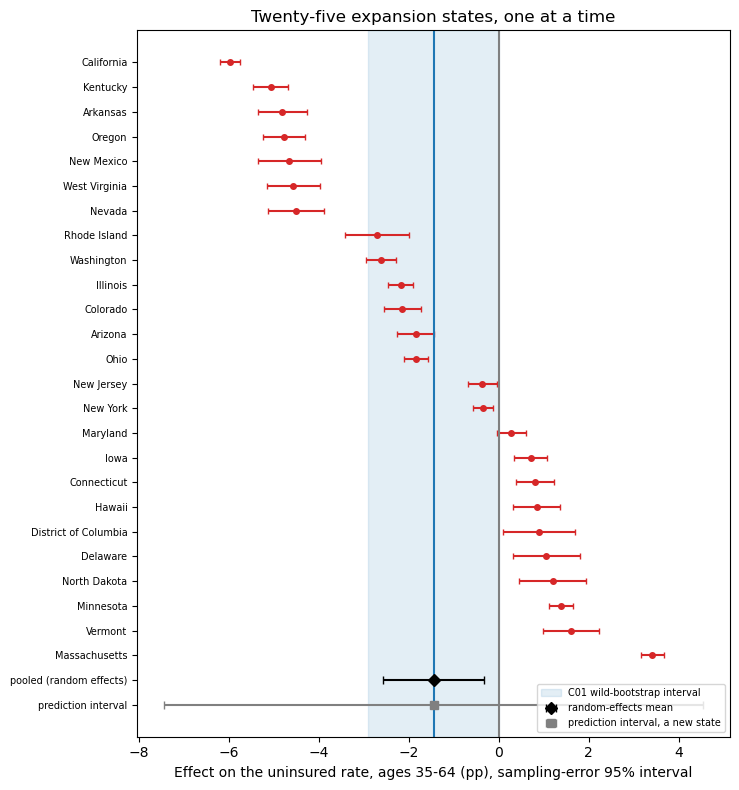

In [8]:
"""Forest plot of the 25 state estimates with the pooled estimates and C01's interval."""
order = main.sort_values("estimate").index
fig, ax = plt.subplots(figsize=(7.5, 8))
ypos = np.arange(len(order))[::-1] + 2.0
ax.errorbar(main.loc[order, "estimate"], ypos, xerr=1.96 * main.loc[order, "se"], fmt="o", color="tab:red", capsize=2, markersize=4)
ax.errorbar([pooled.random_effect], [1.0], xerr=[[pooled.random_effect - re_lo], [re_hi - pooled.random_effect]], fmt="D", color="black", capsize=3, label="random-effects mean")
ax.errorbar([pooled.random_effect], [0.0], xerr=[[pooled.random_effect - pred_lo], [pred_hi - pooled.random_effect]], fmt="s", color="grey", capsize=3, label="prediction interval, a new state")
ax.axvspan(C01["lo"], C01["hi"], color="tab:blue", alpha=0.12, label="C01 wild-bootstrap interval")
ax.axvline(C01["att"], color="tab:blue")
ax.axvline(0, color="grey")
ax.set_yticks(list(ypos) + [1.0, 0.0])
ax.set_yticklabels(list(order) + ["pooled (random effects)", "prediction interval"], fontsize=7)
ax.set_xlabel("Effect on the uninsured rate, ages 35-64 (pp), sampling-error 95% interval")
ax.set_title("Twenty-five expansion states, one at a time")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

Egger's test: intercept -1.699, t = -0.20 on 23 df, p = 0.841 (k = 25; low power below about ten estimates, and this k is 25)


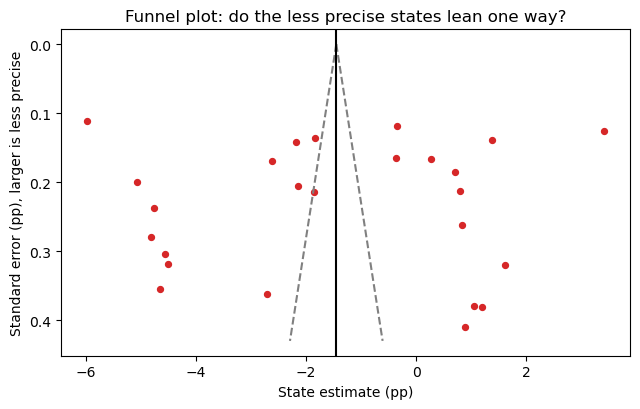

                      random_effect   tau2  i2_pct  shift
state                                                    
Massachusetts                -1.658  6.314  99.403 -0.205
Vermont                      -1.580  8.068  99.568 -0.127
Minnesota                    -1.572  8.070  99.539 -0.119
North Dakota                 -1.563  8.095  99.571 -0.109
Delaware                     -1.557  8.102  99.572 -0.104
District of Columbia         -1.549  8.106  99.573 -0.096
Hawaii                       -1.549  8.154  99.569 -0.095
Connecticut                  -1.548  8.197  99.566 -0.094
Iowa                         -1.544  8.250  99.565 -0.090
Maryland                     -1.526  8.385  99.567 -0.072
New York                     -1.499  8.864  99.569 -0.046
New Jersey                   -1.499  8.492  99.572 -0.045
Ohio                         -1.437  8.748  99.574  0.017
Arizona                      -1.437  8.349  99.574  0.017
Colorado                     -1.424  8.356  99.574  0.029
Illinois      

In [9]:
"""Funnel plot, Egger's regression test and the leave-one-out series."""
egger = meta.egger_test(y, se)
print(f"Egger's test: intercept {egger.intercept:+.3f}, t = {egger.t_stat:.2f} on {egger.df} df, p = {egger.p_value:.3f} (k = {len(y)}; low power below about ten estimates, and this k is {len(y)})")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(y, se, color="tab:red", s=18)
grid = np.linspace(0, se.max() * 1.05, 50)
ax.plot(pooled.random_effect - 1.96 * grid, grid, "--", color="grey")
ax.plot(pooled.random_effect + 1.96 * grid, grid, "--", color="grey")
ax.axvline(pooled.random_effect, color="black")
ax.invert_yaxis()
ax.set_xlabel("State estimate (pp)")
ax.set_ylabel("Standard error (pp), larger is less precise")
ax.set_title("Funnel plot: do the less precise states lean one way?")
plt.tight_layout()
plt.show()

loo = meta.leave_one_out(y, se)
loo_tab = pd.DataFrame({"state": main.index, "random_effect": [r.random_effect for r in loo], "tau2": [r.tau2 for r in loo], "i2_pct": [100 * r.i2 for r in loo]}).set_index("state")
loo_tab["shift"] = loo_tab["random_effect"] - pooled.random_effect
print(loo_tab.round(3).sort_values("shift").to_string())
big = loo_tab["shift"].abs().idxmax()
print(f"Leave-one-out: the pooled random effect ranges {loo_tab['random_effect'].min():+.3f} to {loo_tab['random_effect'].max():+.3f} pp; omitting {big} moves it most, by {loo_tab.loc[big, 'shift']:+.3f} pp "
      f"(tau^2 {loo_tab.loc[big, 'tau2']:.3f} against {pooled.tau2:.3f} with all {len(y)} states).")

### Falsification 1: a placebo timing

The same 25 state estimates are rebuilt on a window that predates the expansion: the change from 2010–2011 to 2012–2013. Pooled by random effects, the effect should be zero.

In [10]:
"""Falsification 1: the pooled placebo-timing effect, 2012-2013 against 2010-2011."""
plc = state_estimates(rates, ses, PLACEBO_PRE, PLACEBO_POST)
pp = meta.pool(plc["estimate"].to_numpy(), plc["se"].to_numpy())
lo1, hi1 = pp.random_effect - 1.96 * pp.random_se, pp.random_effect + 1.96 * pp.random_se
TIMING_PASS = lo1 <= 0.0 <= hi1
print(f"FALSIFICATION: placebo timing, 2012-2013 against 2010-2011 | statistic={pp.random_effect:.3f} | pooled random-effects effect in pp, 95% CI [{lo1:+.3f}, {hi1:+.3f}], tau^2={pp.tau2:.3f}, I^2={100 * pp.i2:.1f}% | verdict={'PASS' if TIMING_PASS else 'FAIL'}")

FALSIFICATION: placebo timing, 2012-2013 against 2010-2011 | statistic=0.100 | pooled random-effects effect in pp, 95% CI [-0.119, +0.318], tau^2=0.177, I^2=64.7% | verdict=PASS


### Falsification 2: the placebo outcome, ages 65 and over

Medicare covers this group in every state, so expansion should not move its uninsured rate. The 25 state estimates are rebuilt for that outcome and pooled.

In [11]:
"""Falsification 2: the pooled effect on the 65-and-over uninsured rate, main contrast."""
plo = state_estimates(rates65, ses65, PRE, POST)
po = meta.pool(plo["estimate"].to_numpy(), plo["se"].to_numpy())
lo2, hi2 = po.random_effect - 1.96 * po.random_se, po.random_effect + 1.96 * po.random_se
OUTCOME_PASS = lo2 <= 0.0 <= hi2
print(f"FALSIFICATION: placebo outcome, uninsured 65+ | statistic={po.random_effect:.3f} | pooled random-effects effect in pp, 95% CI [{lo2:+.3f}, {hi2:+.3f}], tau^2={po.tau2:.3f}, I^2={100 * po.i2:.1f}% | verdict={'PASS' if OUTCOME_PASS else 'FAIL'}")

FALSIFICATION: placebo outcome, uninsured 65+ | statistic=-0.041 | pooled random-effects effect in pp, 95% CI [-0.129, +0.048], tau^2=0.042, I^2=89.1% | verdict=PASS


### Results, in the units of the outcome

In [12]:
"""Results paragraph: every number is printed here from the computed objects."""
c01_banner()
CREDIBLE = TIMING_PASS and OUTCOME_PASS
print(f"Across the {len(y)} expansion states the random-effects mean effect on the uninsured rate of adults 35-64 is {pooled.random_effect:+.2f} pp, 95% interval [{re_lo:+.2f}, {re_hi:+.2f}] "
      f"(expected sign: negative, as stated in the plan). "
      + ("The interval contains zero, so the pooled effect is not distinguishable from zero." if POOLED_NULL else "The interval excludes zero."))
w_re, w_c01 = re_hi - re_lo, C01["hi"] - C01["lo"]
print(f"The random-effects interval is {w_re:.2f} pp wide; C01's wild-bootstrap interval is {w_c01:.2f} pp wide, and C01's "
      + ("contains zero while the pooled one does not" if (C01["lo"] <= 0 <= C01["hi"]) and not POOLED_NULL else "and the pooled one agree on whether zero is inside")
      + ". The pooled interval treats the 25 state estimates as independent although they share one control pool (plan section 8), so it is the narrower and the less trustworthy of the two.")
print(f"The state estimates are not alike: Q = {pooled.q:.1f} on {pooled.df} df, {pf(pooled.p_heterogeneity)}, tau = {np.sqrt(pooled.tau2):.2f} pp, I^2 = {100 * pooled.i2:.1f}%. "
      + ("By the plan's rule heterogeneity is a finding." if HETEROGENEITY else "By the plan's rule the heterogeneity is not distinguishable from zero with these estimates; Q has low power, and tau is reported anyway."))
print(f"A new expansion state's effect would fall in [{pred_lo:+.2f}, {pred_hi:+.2f}] pp with 95% probability under the random-effects model, a range "
      f"{(pred_hi - pred_lo) / (re_hi - re_lo):.1f} times as wide as the interval for the mean.")
print(f"A floor for reading tau: in the placebo-timing contrast, where no expansion effect is expected, the states still differ (tau = {np.sqrt(pp.tau2):.2f} pp, I^2 = {100 * pp.i2:.1f}%), "
      f"against tau = {np.sqrt(pooled.tau2):.2f} pp in the main contrast. Variation of that size arises without an expansion effect.")
n_neg = int((main["estimate"] < 0).sum())
n_excl = int(((main["hi"] < 0) | (main["lo"] > 0)).sum())
print(f"{n_neg} of {len(y)} state estimates are negative; {n_excl} have a sampling-error 95% interval that excludes zero (sampling error alone; these intervals are narrow because each state's margins of error are small relative to the differences between states). Range of estimates: {main['estimate'].min():+.2f} to {main['estimate'].max():+.2f} pp.")
print(f"Fixed-effect and random-effects means differ ({pooled.fixed_effect:+.2f} against {pooled.random_effect:+.2f} pp); the unweighted mean of the state estimates is C01's ATT ({mean_est:+.2f} pp).")
print(f"Placebos: timing {'passes' if TIMING_PASS else 'fails'}, outcome {'passes' if OUTCOME_PASS else 'fails'}; "
      + ("by the plan's rule the pooled effect is read as identified." if CREDIBLE else "by the plan's rule the pooled effect is descriptive, not identified."))

C01 (read from its stored output, not re-run): ATT -1.453 pp, wild-bootstrap 95% interval [-2.912, +0.006], p = 0.051.
  Borderline and seed-sensitive: the 9,999-draw interval contains zero (upper end +0.006), while at 99,999 draws p runs 0.0474 to 0.0482 and the upper end -0.020 to -0.013 across three seeds.
Across the 25 expansion states the random-effects mean effect on the uninsured rate of adults 35-64 is -1.45 pp, 95% interval [-2.57, -0.34] (expected sign: negative, as stated in the plan). The interval excludes zero.
The random-effects interval is 2.24 pp wide; C01's wild-bootstrap interval is 2.92 pp wide, and C01's contains zero while the pooled one does not. The pooled interval treats the 25 state estimates as independent although they share one control pool (plan section 8), so it is the narrower and the less trustworthy of the two.
The state estimates are not alike: Q = 5410.7 on 24 df, p < 0.0001, tau = 2.84 pp, I^2 = 99.6%. By the plan's rule heterogeneity is a finding.
A

### Added after the first run: not pre-specified (added after the first run, 2026-10-27)

The cell below was added after the stored results were seen. It does not replace the plan's primary result. Ten of the 25 expansion states had broad adult coverage before 2014 or an early expansion option,
which C01's Limitations lists; the cell pools without them and asks whether the heterogeneity depends on them.

In [13]:
"""not pre-specified (added after the first run, 2026-10-27): pooling without the ten expansion states with earlier adult coverage."""
EARLY = ["California", "Connecticut", "Delaware", "District of Columbia", "Massachusetts", "Minnesota", "New Jersey", "New York", "Vermont", "Washington"]
assert set(EARLY) <= set(TREATED), "every listed state must be one of the 25 expansion states"
rest = main.drop(index=EARLY)
pr = meta.pool(rest["estimate"].to_numpy(), rest["se"].to_numpy())
pr_lo, pr_hi = pr.random_effect - 1.96 * pr.random_se, pr.random_effect + 1.96 * pr.random_se
pr_pi = meta.prediction_interval(pr)
print(f"without the {len(EARLY)} early-coverage states ({len(rest)} remain): random-effects {pr.random_effect:+.3f} pp, 95% interval [{pr_lo:+.3f}, {pr_hi:+.3f}]; "
      f"Q = {pr.q:.2f} on {pr.df} df, {pf(pr.p_heterogeneity)}; tau^2 = {pr.tau2:.3f}; I^2 = {100 * pr.i2:.1f}%; prediction interval [{pr_pi[0]:+.3f}, {pr_pi[1]:+.3f}]")
early = main.loc[EARLY]
print(f"the {len(EARLY)} early-coverage states alone: mean estimate {early['estimate'].mean():+.3f} pp against {rest['estimate'].mean():+.3f} pp for the other {len(rest)}")
print(f"The pooled mean moves from {pooled.random_effect:+.3f} to {pr.random_effect:+.3f} pp and tau^2 from {pooled.tau2:.3f} to {pr.tau2:.3f} when they are left out.")

without the 10 early-coverage states (15 remain): random-effects -2.406 pp, 95% interval [-3.453, -1.359]; Q = 1262.56 on 14 df, p < 0.0001; tau^2 = 4.212; I^2 = 98.9%; prediction interval [-6.988, +2.175]
the 10 early-coverage states alone: mean estimate -0.018 pp against -2.409 pp for the other 15
The pooled mean moves from -1.453 to -2.406 pp and tau^2 from 8.073 to 4.212 when they are left out.


## Limitations

- **The state estimates are not independent.** Every one is measured against the same ten never-expanded states, so a chance fluctuation in the control group moves all of them together. The pooling treats them as independent, so every pooled interval above is too narrow, and the prediction interval is too. This notebook does not say by how much.
- **Standard errors are sampling errors only.** They come from the published margins of error and treat the years as independent samples. Differences between states that these errors do not explain are called between-state variance, τ², but they also include any year-level noise in the comparison that the margins of error do not capture.
- **Single-state estimates are noisy by design.** Each compares one state with ten controls. The sampling-error intervals above are the honest range of each; the table's ordering is partly noise.
- **τ² is imprecise.** The DerSimonian–Laird moment estimator is imprecise with 25 estimates and the interval uses the normal quantile without a Hartung–Knapp adjustment. Cochran's Q has low power at this number of studies.
- **Funnel plot and Egger's test.** With 25 estimates, and estimates that share a control group, asymmetry is hard to read and the test has little power.
- **Contaminated comparisons.** Several expansion states already had broad adult coverage or an early expansion option before 2014, and one control state, Wisconsin, covered adults up to the poverty level from April 2014; C01's Limitations lists them. The added analysis above leaves out the ten early-coverage expansion states and is not part of the plan.
- **Carried from C01.** The 2014-cohort design, the choice of age band 35–64, and the comparison against the non-expansion states' own version of the ACA carry over. C01's estimate is itself borderline, and the unweighted mean of the state estimates equals it.
- **Departures from the plan.** The analysis did not depart from the pre-analysis plan's estimators, standard errors, pooling, falsification tests or decision rules. One analysis was added that the plan did not specify, labelled "not pre-specified (added after the first run, 2026-10-27)" in its cell: the pooling without the ten early-coverage states. It does not replace the plan's primary result. 2020 is missing.

## Key Takeaways

1. A pooled average is only believable if the pieces it averages agree. Here the pieces are the states, and the notebook prints how far they disagree beyond sampling error (τ², I², the prediction interval) next to the average itself.
2. The fixed-effect and random-effects means answer different questions: the one common effect, and the mean of a distribution of effects. When the states differ, the prediction interval, not the interval for the mean, says what to expect in a new state.
3. The state estimates share a control group, so the pooled intervals are narrower than the evidence supports. The number of states does not fix that.
4. Heterogeneity is a finding to report, not noise to average away; and the average of the states is C01's estimate, with C01's borderline status.

## Exercises

1. Replace the control pool of ten states with each control state in turn, leaving it out, and re-estimate the 25 state effects. How much of the between-state variance moves with the control pool?
2. Weight the control pool by 2013 population aged 35–64. Which state estimates change most, and does the pooled mean move toward the population-weighted estimate in C01?
3. Compute the prediction interval with the Hartung–Knapp adjustment for the mean. How much wider does the interval for the mean become?
4. Treat each control state as if it were expanded and estimate its effect against the other nine. What does the spread of those placebo estimates say about the standard errors used here?

## References

- DerSimonian, R., and Laird, N. (1986). Meta-analysis in clinical trials. *Controlled Clinical Trials*, 7(3), 177–188.
- Higgins, J. P. T., Thompson, S. G., and Spiegelhalter, D. J. (2009). A re-evaluation of random-effects meta-analysis. *Journal of the Royal Statistical Society: Series A*, 172(1), 137–159.
- Egger, M., Davey Smith, G., Schneider, M., and Minder, C. (1997). Bias in meta-analysis detected by a simple, graphical test. *BMJ*, 315, 629–634.
- Higgins, J. P. T., and Thompson, S. G. (2002). Quantifying heterogeneity in a meta-analysis. *Statistics in Medicine*, 21(11), 1539–1558.
- U.S. Census Bureau. American Community Survey 1-year detail table B27010 and its margins of error, variable documentation.
- KFF. *Status of State Action on the Medicaid Expansion Decision* (see `data/policy/medicaid/SOURCES.md`).